# Preprocessing Teks Ulasan E-Commerce Berbahasa Indonesia untuk Analisis Sentimen

**Mata Kuliah:** Natural Language Processing  
**Nama:** [Isi Nama Anda di Sini]  
**NIM:** [Isi NIM Anda di Sini]  
**Dataset:** [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment)  
**GitHub:** [Isi URL Repositori GitHub]

Notebook ini berisi tugas preprocessing teks ulasan produk e-commerce. Data yang dipakai adalah ulasan berbahasa Indonesia dari Hugging Face. Saya mengerjakan lima tahap preprocessing, menampilkan 10 contoh sebelum dan sesudah, lalu menjelaskan pengaruhnya terhadap kualitas data.


## 1. Import Library

Library yang saya pakai: pandas untuk mengolah tabel, matplotlib dan seaborn untuk grafik, serta Sastrawi untuk stopword removal dan stemming bahasa Indonesia.


In [1]:
import json
import os
import re
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)


## 2. Memuat Dataset

Dataset diambil dari Hugging Face. Saya menyimpan file JSON-nya di folder yang sama supaya notebook tetap bisa dijalankan tanpa internet. Kalau file belum ada, kode di bawah akan mengunduhnya.


In [2]:
url = "https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment/resolve/main/labeledReview.datasetFix.json"
file_lokal = "labeledReview.datasetFix.json"

if os.path.exists(file_lokal):
    with open(file_lokal, encoding="utf-8") as f:
        data = json.load(f)
    print("Data dimuat dari file lokal.")
else:
    with urllib.request.urlopen(url) as response:
        data = json.loads(response.read().decode("utf-8"))
    with open(file_lokal, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False)
    print("Data berhasil diunduh dari Hugging Face.")

df = pd.DataFrame(data)
print("Jumlah data:", len(df))
df[["review", "sentimen"]].head()


Data dimuat dari file lokal.
Jumlah data: 11606


,review,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,0
1,Good. Mudah-mudahan awet. Makasih,1
2,"kondisi dus robek2, tolong di perhatikan lagi",0
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,0
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",0


## 3. Informasi Dataset

Pada bagian ini saya cek jumlah baris, nama kolom, tipe data, nilai kosong, dan jumlah ulasan yang teksnya duplikat. Kolom `translate` berisi terjemahan bahasa Inggris dan tidak saya pakai pada proses preprocessing.


In [3]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
print("Nama kolom   :", df.columns.tolist())
print()
print("Tipe data:")
print(df.dtypes)
print()
print("Nilai kosong per kolom:")
print(df.isnull().sum())
print()
print("Jumlah review duplikat:", df.duplicated(subset="review").sum())


Jumlah baris : 11606
Jumlah kolom : 3
Nama kolom   : ['review', 'sentimen', 'translate']

Tipe data:
review         str
sentimen     int64
translate      str
dtype: object

Nilai kosong per kolom:
review       0
sentimen     0
translate    0
dtype: int64

Jumlah review duplikat: 7


### Distribusi Label Sentimen

Label 0 berarti negatif dan 1 berarti positif. Saya hitung jumlah masing-masing label, lalu menggambarkannya dalam grafik batang dan diagram lingkaran.


,Sentimen,Jumlah,Persentase (%)
0,Negatif (0),5803,50.0
1,Positif (1),5803,50.0


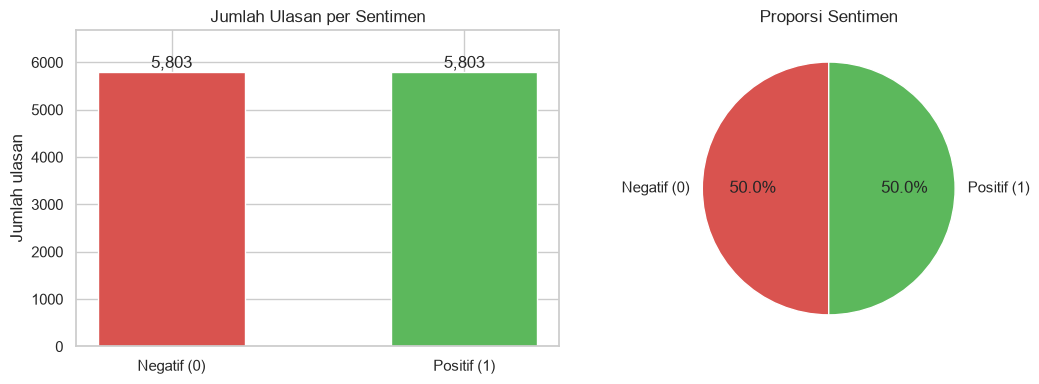

Ulasan negatif: 5,803 (50.0%)
Ulasan positif: 5,803 (50.0%)


In [4]:
jumlah = df["sentimen"].value_counts().sort_index()
persen = df["sentimen"].value_counts(normalize=True).sort_index() * 100

distribusi = pd.DataFrame({
    "Sentimen": ["Negatif (0)", "Positif (1)"],
    "Jumlah": jumlah.values,
    "Persentase (%)": persen.round(2).values,
})
display(distribusi)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

warna = ["#d9534f", "#5cb85c"]
batang = ax[0].bar(distribusi["Sentimen"], distribusi["Jumlah"], color=warna, width=0.5)
ax[0].set_title("Jumlah Ulasan per Sentimen")
ax[0].set_ylabel("Jumlah ulasan")
ax[0].set_ylim(0, max(jumlah) * 1.15)
for b in batang:
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 80,
               f"{int(b.get_height()):,}", ha="center")

ax[1].pie(distribusi["Jumlah"], labels=distribusi["Sentimen"], autopct="%1.1f%%",
          colors=warna, startangle=90, wedgeprops={"edgecolor": "white"})
ax[1].set_title("Proporsi Sentimen")

plt.tight_layout()
plt.show()

print(f"Ulasan negatif: {jumlah[0]:,} ({persen[0]:.1f}%)")
print(f"Ulasan positif: {jumlah[1]:,} ({persen[1]:.1f}%)")


## 4. Preprocessing Teks

Preprocessing dilakukan dalam lima tahap:

1. **Case folding**: mengubah semua huruf menjadi kecil.
2. **Cleaning**: menghapus URL, angka, tanda baca, emoji, dan karakter selain huruf.
3. **Tokenisasi**: memecah kalimat menjadi kata.
4. **Stopword removal**: menghapus kata umum yang tidak membawa makna, seperti "dan", "yang", dan "di".
5. **Stemming**: mengubah kata berimbuhan menjadi kata dasar dengan Sastrawi.

Saya juga memperhatikan bahwa stopword Sastrawi memuat kata negasi seperti *tidak* dan *kurang*. Kalau kata itu ikut dihapus, makna kalimat bisa berubah. Jadi kata negasi saya keluarkan dari daftar stopword.


In [5]:
stopword_awal = set(StopWordRemoverFactory().get_stop_words())
negasi = {"tidak", "bukan", "jangan", "belum", "kurang", "tanpa",
          "tak", "gak", "ga", "nggak", "tdk"}
stopword = stopword_awal - negasi

stemmer = StemmerFactory().create_stemmer()
cache_stem = {}

def stem_kata(kata):
    if kata not in cache_stem:
        cache_stem[kata] = stemmer.stem(kata)
    return cache_stem[kata]

print("Jumlah stopword Sastrawi:", len(stopword_awal))
print("Jumlah kata negasi yang dipertahankan:", len(negasi))
print("Jumlah stopword yang dipakai:", len(stopword))


Jumlah stopword Sastrawi:

 809
Jumlah kata negasi yang dipertahankan: 11
Jumlah stopword yang dipakai: 802


In [6]:
def case_folding(teks):
    return str(teks).lower()

def cleaning(teks):
    teks = re.sub(r"https?://\S+|www\.\S+", " ", teks)   # URL
    teks = re.sub(r"\d+", " ", teks)                     # angka
    teks = re.sub(r"[^a-z\s]", " ", teks)                # tanda baca dan karakter lain
    teks = re.sub(r"\s+", " ", teks).strip()             # spasi berlebih
    return teks

def tokenisasi(teks):
    return teks.split()

def hapus_stopword(tokens):
    return [kata for kata in tokens if kata not in stopword and len(kata) > 1]

def stemming(tokens):
    return [stem_kata(kata) for kata in tokens]


### Uji Coba pada Satu Ulasan

Sebelum dipakai ke semua data, saya coba dulu ke ulasan pertama supaya perubahan di tiap tahap terlihat.


In [7]:
teks = df.loc[0, "review"]

print("Teks asli:")
print(teks)

hasil = case_folding(teks)
print("\n1. Case folding:")
print(hasil)

hasil = cleaning(hasil)
print("\n2. Cleaning:")
print(hasil)

tokens = tokenisasi(hasil)
print("\n3. Tokenisasi:")
print(tokens)

tokens = hapus_stopword(tokens)
print("\n4. Stopword removal:")
print(tokens)

tokens = stemming(tokens)
print("\n5. Stemming:")
print(tokens)

print("\nHasil akhir:")
print(" ".join(tokens))


Teks asli:
Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala

1. Case folding:
suara dan mic puas. hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala

2. Cleaning:
suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala

3. Tokenisasi:
['suara', 'dan', 'mic', 'puas', 'hanya', 'saya', 'pesan', 'yg', 'nyala', 'dan', 'sudah', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'datang', 'ga', 'nyala']

4. Stopword removal:
['suara', 'mic', 'puas', 'pesan', 'yg', 'nyala', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'ga', 'nyala']

5. Stemming:
['suara', 'mic', 'puas', 'pesan', 'yg', 'nyala', 'sy', 'pasti', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'ga', 'nyala']

Hasil akhir:
suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg ga nyala


### Menerapkan Preprocessing ke Seluruh Data

Fungsi di atas saya terapkan ke semua baris. Hasil setiap tahap saya simpan di kolom baru supaya bisa diperiksa.


In [8]:
mulai = time.time()

df["case_folding"] = df["review"].apply(case_folding)
df["cleaning"] = df["case_folding"].apply(cleaning)
df["tokens"] = df["cleaning"].apply(tokenisasi)
df["tokens_tanpa_stopword"] = df["tokens"].apply(hapus_stopword)
df["tokens_stem"] = df["tokens_tanpa_stopword"].apply(stemming)
df["clean_review"] = df["tokens_stem"].apply(" ".join)

selesai = time.time()
print(f"Proses selesai dalam {selesai - mulai:.2f} detik.")
print(f"Jumlah kata unik yang di-stem: {len(cache_stem):,}")


Proses selesai dalam 1.56 detik.
Jumlah kata unik yang di-stem: 12,052


## 5. Contoh Sebelum dan Sesudah Preprocessing

Berikut 10 ulasan yang saya pilih. Saya usahakan ada campuran ulasan negatif dan positif, teks panjang dan pendek, serta teks yang mengandung angka, tanda baca, dan singkatan.


In [9]:
indeks = [0, 1, 2, 3, 4, 15, 27, 42, 105, 500]

contoh = df.loc[indeks, ["review", "clean_review", "sentimen"]].copy()
contoh["sentimen"] = contoh["sentimen"].map({0: "Negatif (0)", 1: "Positif (1)"})
contoh = contoh[["sentimen", "review", "clean_review"]]
contoh.columns = ["Sentimen", "Sebelum Preprocessing", "Sesudah Preprocessing"]
contoh.index = range(1, len(contoh) + 1)
contoh.index.name = "No"
display(contoh)

,Sentimen,Sebelum Preprocessing,Sesudah Preprocessing
No,,,
1,Negatif (0),Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg ga nyala
2,Positif (1),Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
3,Negatif (0),"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek tolong perhati
4,Negatif (0),Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk harga jangkau kirim cepet banget udh order oke tp sayang klo kado gabisa nitip pake kartu ucap bungkus pake kertas kado
5,Negatif (0),"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi packaging kurang penyot robek
6,Negatif (0),Pengiriman sangat cepat cuma 2 hari . barang berpungsi sangat baik . cuma packingnya aja yg kurang aman . untungnya semua barangnya gak ada yg cacat sedikitpun 👍🏻,kirim cepat barang pungsi packingnya aja yg kurang aman untung barang gak yg cacat sedikit
7,Positif (1),respon seller cepet bgt...barang nya oke sesuai deskripsi..thx u,respon seller cepet bgt barang oke sesuai deskripsi thx
8,Negatif (0),Barang sy dr tgl 29des. Smpai hr ini tdk smpai2. Sy bayar ongkir ekspres sampai hri yg sama tp nyatanya 0! Mengecewakan! Ga layak ada di lazada,barang sy dr tgl des smpai hr tdk smpai sy bayar ongkir ekspres hri yg tp kecewa ga layak lazada
9,Positif (1),Mantab all item complete,mantab all item complete


### Catatan Kualitas

Setelah preprocessing, saya cek apakah ada ulasan yang jadi kosong atau terlalu pendek. Ini perlu dicatat karena bisa memengaruhi analisis berikutnya.


In [10]:
kosong = (df["clean_review"].str.strip() == "").sum()
pendek = (df["clean_review"].str.split().str.len() <= 2).sum()

print(f"Ulasan kosong setelah preprocessing: {kosong} dari {len(df):,} ({kosong / len(df) * 100:.2f}%)")
print(f"Ulasan dengan 2 token atau kurang  : {pendek} dari {len(df):,} ({pendek / len(df) * 100:.2f}%)")


Ulasan kosong setelah preprocessing: 18 dari 11,606 (0.16%)
Ulasan dengan 2 token atau kurang  : 758 dari 11,606 (6.53%)


## 6. Perbandingan Statistik

Untuk melihat pengaruh preprocessing secara kuantitatif, saya bandingkan panjang karakter, jumlah kata, dan jumlah kosakata unik sebelum dan sesudah.


,Indikator,Sebelum,Sesudah,Turun (%)
0,Rata-rata panjang karakter,103.57,67.40,34.9
1,Median panjang karakter,78.0,52.0,33.3
2,Rata-rata jumlah kata,15.76,11.08,29.7
3,Median jumlah kata,12.0,9.0,25.0
4,Jumlah kata terbanyak,235,127,46.0
5,Kosakata unik,"23,371","10,040",57.0


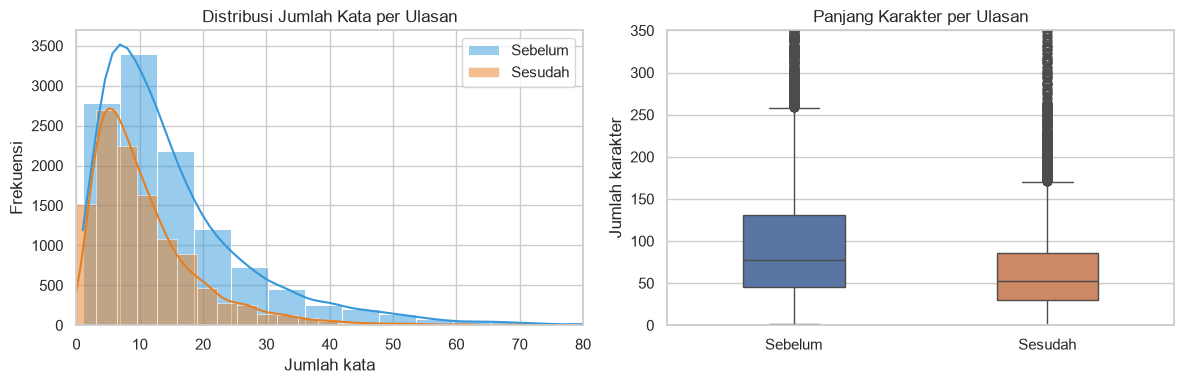

In [11]:
df["jumlah_karakter_awal"] = df["review"].str.len()
df["jumlah_karakter_akhir"] = df["clean_review"].str.len()
df["jumlah_kata_awal"] = df["review"].str.split().str.len()
df["jumlah_kata_akhir"] = df["clean_review"].str.split().str.len()

kosakata_awal = set(kata for teks in df["review"].str.lower() for kata in teks.split())
kosakata_akhir = set(kata for teks in df["clean_review"] for kata in teks.split() if kata)

ringkasan = pd.DataFrame({
    "Indikator": [
        "Rata-rata panjang karakter",
        "Median panjang karakter",
        "Rata-rata jumlah kata",
        "Median jumlah kata",
        "Jumlah kata terbanyak",
        "Kosakata unik",
    ],
    "Sebelum": [
        f"{df['jumlah_karakter_awal'].mean():.2f}",
        f"{df['jumlah_karakter_awal'].median():.1f}",
        f"{df['jumlah_kata_awal'].mean():.2f}",
        f"{df['jumlah_kata_awal'].median():.1f}",
        f"{df['jumlah_kata_awal'].max()}",
        f"{len(kosakata_awal):,}",
    ],
    "Sesudah": [
        f"{df['jumlah_karakter_akhir'].mean():.2f}",
        f"{df['jumlah_karakter_akhir'].median():.1f}",
        f"{df['jumlah_kata_akhir'].mean():.2f}",
        f"{df['jumlah_kata_akhir'].median():.1f}",
        f"{df['jumlah_kata_akhir'].max()}",
        f"{len(kosakata_akhir):,}",
    ],
})
ringkasan["Turun (%)"] = [
    f"{(1 - df['jumlah_karakter_akhir'].mean() / df['jumlah_karakter_awal'].mean()) * 100:.1f}",
    f"{(1 - df['jumlah_karakter_akhir'].median() / df['jumlah_karakter_awal'].median()) * 100:.1f}",
    f"{(1 - df['jumlah_kata_akhir'].mean() / df['jumlah_kata_awal'].mean()) * 100:.1f}",
    f"{(1 - df['jumlah_kata_akhir'].median() / df['jumlah_kata_awal'].median()) * 100:.1f}",
    f"{(1 - df['jumlah_kata_akhir'].max() / df['jumlah_kata_awal'].max()) * 100:.1f}",
    f"{(1 - len(kosakata_akhir) / len(kosakata_awal)) * 100:.1f}",
]

display(ringkasan)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["jumlah_kata_awal"], bins=40, color="#3498db", label="Sebelum", ax=ax[0], kde=True)
sns.histplot(df["jumlah_kata_akhir"], bins=40, color="#e67e22", label="Sesudah", ax=ax[0], kde=True)
ax[0].set_title("Distribusi Jumlah Kata per Ulasan")
ax[0].set_xlabel("Jumlah kata")
ax[0].set_ylabel("Frekuensi")
ax[0].set_xlim(0, 80)
ax[0].legend()

sns.boxplot(data=df[["jumlah_karakter_awal", "jumlah_karakter_akhir"]], ax=ax[1], width=0.4)
ax[1].set_title("Panjang Karakter per Ulasan")
ax[1].set_xticklabels(["Sebelum", "Sesudah"])
ax[1].set_ylabel("Jumlah karakter")
ax[1].set_ylim(0, 350)

plt.tight_layout()
plt.show()


## 7. Pengaruh Preprocessing terhadap Kualitas Data

Setelah dibandingkan, rata-rata panjang karakter turun dari 103,57 menjadi 67,40 (turun 34,9%). Rata-rata jumlah kata turun dari 15,76 menjadi 11,08 (turun 29,7%). Jumlah kosakata unik juga turun cukup banyak, dari 23.371 menjadi 10.040 kata (turun 57,0%).

Penurunan ini terjadi karena banyak bagian teks yang memang tidak diperlukan ikut dibuang, seperti URL, angka, tanda baca, emoji, dan stopword. Selain itu, case folding dan stemming membuat bentuk kata yang berbeda menjadi satu. Misalnya "pengiriman", "dikirim", dan "kirim" sama-sama menjadi "kirim". Akibatnya, jumlah fitur yang harus diproses menjadi lebih sedikit.

Menurut saya, hasil ini cukup membantu karena teks jadi lebih seragam dan lebih mudah dianalisis. Namun, ada beberapa hal yang perlu diperhatikan. Singkatan seperti "yg", "tp", "gak", dan "bgt" masih muncul karena saya belum melakukan normalisasi slang. Stemming Sastrawi juga kadang memotong kata terlalu jauh, misalnya "perhatikan" menjadi "perhati". Selanjutnya, ada 18 ulasan yang menjadi kosong dan 758 ulasan yang tersisa 2 kata atau kurang, sehingga konteks sentimennya bisa hilang.

Karena itu, hasil preprocessing ini sudah cukup untuk tahap eksplorasi, tetapi belum tentu cukup untuk melatih model klasifikasi sentimen. Kalau ingin dilanjutkan ke pemodelan, sebaiknya ditambahkan kamus normalisasi slang dan penanganan khusus untuk ulasan yang terlalu pendek.


## 8. Kesimpulan

Dataset berhasil dimuat dengan 11.606 ulasan dan 3 kolom. Distribusi labelnya seimbang, yaitu 5.803 ulasan negatif dan 5.803 ulasan positif. Lima tahap preprocessing juga berhasil dijalankan pada seluruh data. Dari 10 contoh yang ditampilkan, teks menjadi lebih pendek dan lebih rapi, tetapi masih ada singkatan yang belum dinormalisasi. Secara keseluruhan, preprocessing membuat data lebih siap dianalisis, dengan catatan keterbatasan yang sudah dijelaskan di bagian sebelumnya.
